# Synthetic posts from Distil Labs: what we got

The training sentences look nothing like the test posts (adversarial AUC 0.99, see
`adversarial_validation.ipynb`). So we asked Distil Labs to write new Telegram-style posts with labels,
using half of the pseudo-labeled test posts (seed half A, 239 posts) as examples
(`prepare_distil.py`). The teacher is GLM 5.3; another GLM call re-labels every post and rejects the
ones where the two label lists differ. The run asked for 6,000 posts.

This notebook checks the result before we train on it:

1. Load the run and drop the seed posts it copies back.
2. Check the labels: valid JSON, every string really in the text.
3. Compare the format with the test posts: length, line breaks, emoji, language.
4. Compare the labels: places per post, which places, how many are new.
5. Look for copies: of test posts and of each other.
6. Save a clean table with character spans for NER training.

The adversarial check (can XLM-R tell synthetic from test posts?) is in `synthetic_adversarial.ipynb`.

In [1]:
import ast
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import AutoTokenizer

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT.parent))
import synth_data as sd
from evaluation.metric import published_normalize

RUN = ROOT / "runs" / "full-1"
OUT = ROOT / "output"
OUT.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 120)

## 1. Load the run

Distil puts the seed posts into `train.jsonl` next to the generated ones, so we remove every row whose
text equals a seed. The test posts with their pseudo-labels come from `pseudo_label/`.

In [2]:
syn = sd.load_run(RUN)
test = pd.read_parquet(ROOT.parent / "pseudo_label" / "output" / "test_pseudo.parquet")
test["locations"] = test["locations"].map(list)

n_rows = sum(1 for _ in (RUN / "train.jsonl").open(encoding="utf-8"))
print(f"rows in train.jsonl: {n_rows}, seed posts removed: {n_rows - len(syn)}, generated posts: {len(syn)}")
print(f"test posts: {len(test)} (seed half A: {(test.seed_half == 'A').sum()}, half B: {(test.seed_half == 'B').sum()})")

rows in train.jsonl: 6318, seed posts removed: 239, generated posts: 6079
test posts: 477 (seed half A: 239, half B: 238)


## 2. Are the labels usable?

The answer must be a JSON list of strings copied exactly from the post. We strip punctuation from both
ends of every string (we do the same before every submission) and look for each string in the text as a
whole word. Rows where any string is missing can't be turned into spans.

Quotes need care: "станції метро «Оболонь»" keeps both quotes (stripping only the last one would leave a
half-quoted label and a span one character short), while a name wrapped whole, "«Почайна»", loses both,
since the gold labels have no quotes.

In [3]:
syn["locations"] = syn["locations"].map(lambda p: sd.tidy_locations(p) if p is not None else None)
syn = sd.add_spans(syn)
bad_json = syn.locations.isna()
missing = syn.missing.map(bool)
print(f"answers that are not a JSON list of strings: {bad_json.sum()}")
print(f"rows with a string not found in the text: {missing.sum()} ({missing.mean():.1%})")
syn.loc[missing, ["missing", "text"]].assign(text=lambda d: d.text.str.slice(0, 110).str.replace("\n", " ")).head(8)

answers that are not a JSON list of strings: 0
rows with a string not found in the text: 44 (0.7%)


,missing,text
196,[пр. Московському],ДТП на Оболоні: легковик зіткнувся з маршруткою біля ст. м. Оболонь. Рух по Оболонському проспекту у бік вул.
410,"[улица Голосеевская, 12-40]",🚧 В Голосеевском районе перекроют движение из-за замены теплотрассы «Киевтеплоэнерго» начинает масштабные раб
418,[вулиці Олександра Верлинського],⚠️ Відключення води у Деснянському районі Київводоканал повідомляє про планові роботи на мережах. 12 жовтня з
457,"[улицы Мишуги, 4–18]","🚧 Внимание, водители: на этой неделе стартует капремонт дорожного покрытия В Дарницком районе коммунальщики п"
705,[провулку Технічному],"🚧 Увага! З 12 серпня на вул. Дружківській, 8 розпочинається капітальний ремонт тепломережі Рух транспорту на"
744,[Київщині],"⛈️ ОГОЛОШЕНО ПОПЕРЕДЖЕННЯ ПРО ГРОЗУ Синоптики повідомляють, що ввечері та вночі на території Київщини очікуют"
870,[Харківському шосе],У Дарницькому районі на Харкївському шосе сталася ДТП за участю двох легковиків. Рух у бік Лівобережної усклад
876,"[вул. Сагайдачного, 15-27]","🎉 У суботу на Подолі відбудеться фестиваль вуличної їжі. Вул. Сагайдачного, 15-27 перекриють для авто — гості"


Almost all of these are the generator changing the ending of a word in the label: the text says
"Київщини" and the label "Київщині", or "провулком Технічним" against "провулку Технічному". The judge
should have caught them but didn't. We can't tell which form was meant, so we drop these rows.

## 3. Does the text look like the test posts?

The same features for the generated posts and the 477 test posts. Length is also counted in XLM-R
tokens, because that is what limits the model (512 at most, we train on shorter windows).

In [4]:
tokenizer = AutoTokenizer.from_pretrained("FacebookAI/xlm-roberta-base")


def describe(frame):
    f = sd.style(frame)
    tokens = pd.Series([len(ids) for ids in tokenizer(list(frame.text), truncation=False)["input_ids"]])
    return pd.Series({
        "posts": len(frame),
        "chars, median": f.chars.median(),
        "chars, p25 / p75": f"{f.chars.quantile(.25):.0f} / {f.chars.quantile(.75):.0f}",
        "chars, max": f.chars.max(),
        "tokens, median": tokens.median(),
        "tokens, p95": tokens.quantile(.95),
        "over 512 tokens": (tokens > 512).sum(),
        "line breaks": f"{f.has_line_break.mean():.0%}",
        "emoji": f"{f.has_emoji.mean():.0%}",
        "links": f"{f.has_link.mean():.0%}",
        "hashtags": f"{f.has_hashtag.mean():.0%}",
        "Russian": f"{(f.lang == 'ru').mean():.0%}",
    }), f.chars, tokens


test_stats, test_chars, test_tokens = describe(test)
syn_stats, syn_chars, syn_tokens = describe(syn)
pd.DataFrame({"test posts": test_stats, "synthetic": syn_stats})

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (729 > 512). Running this sequence through the model will result in indexing errors


,test posts,synthetic
posts,477,6079
"chars, median",264.0,266.0
"chars, p25 / p75",128 / 517,161 / 438
"chars, max",3682,2471
"tokens, median",73.0,74.0
"tokens, p95",314.4,260.0
over 512 tokens,8,20
line breaks,85%,78%
emoji,60%,66%
links,4%,0%


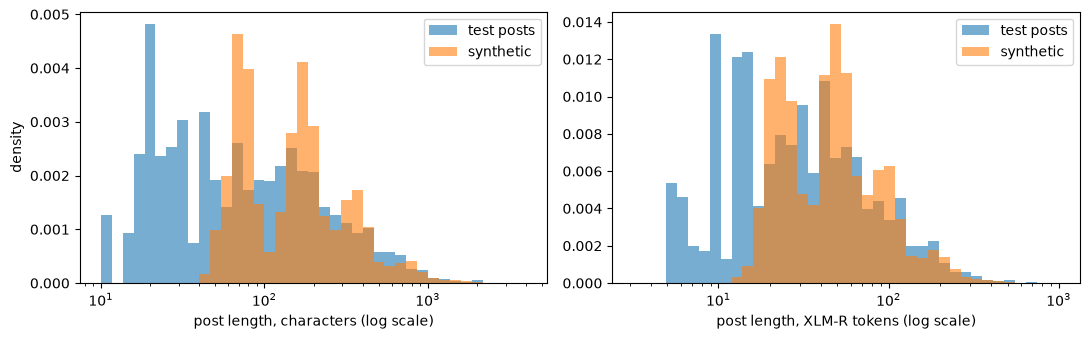

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
bins = np.logspace(1, np.log10(4000), 40)
for ax, (name, a, b) in zip(axes, [("characters", test_chars, syn_chars), ("XLM-R tokens", test_tokens, syn_tokens)]):
    ax.hist(a, bins=bins if name == "characters" else np.logspace(0.5, 3, 40), density=True, alpha=0.6, label="test posts")
    ax.hist(b, bins=bins if name == "characters" else np.logspace(0.5, 3, 40), density=True, alpha=0.6, label="synthetic")
    ax.set_xscale("log")
    ax.set_xlabel(f"post length, {name} (log scale)")
    ax.legend()
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()

The length mutator did its job: the quartiles are close to the test posts, and so are the shares with
line breaks and emoji. Two differences remain. The test set has a long tail of very long posts (up to
3,682 characters) that the generator never reaches, and the synthetic posts almost never have links,
because the instructions didn't ask for them. Neither matters much for NER: long posts get split into
windows anyway, and links rarely contain places.

## 4. Do the labels look like the test labels?

For the test posts we use the teacher's pseudo-labels. Street names with a type word ("вулиці
Хрещатик") matter because the 26 labeled sample posts have 21.9% of them and the training sentences only
2-4%.

In [6]:
def label_stats(frame):
    n = frame.locations.str.len()
    strings = [s for row in frame.locations for s in row]
    counts = Counter(strings)
    return pd.Series({
        "posts with no places": f"{(n == 0).mean():.0%}",
        "places per post, mean": round(n.mean(), 2),
        "posts with 4+ places": f"{(n >= 4).mean():.0%}",
        "place strings": len(strings),
        "distinct strings": len(counts),
        "with a street-type word": f"{np.mean([bool(sd.STREET_TYPE.match(s)) for s in strings]):.0%}",
        "top 10 strings, share": f"{sum(c for _, c in counts.most_common(10)) / len(strings):.0%}",
    })


usable = syn[~bad_json & ~missing]
pd.DataFrame({"test (pseudo-labels)": label_stats(test), "synthetic": label_stats(usable)})

,test (pseudo-labels),synthetic
posts with no places,33%,39%
"places per post, mean",1.5,1.36
posts with 4+ places,11%,11%
place strings,716,8193
distinct strings,414,2407
with a street-type word,10%,25%
"top 10 strings, share",31%,27%


We asked for 30% of posts without places, and got 39%, close to the 33% in the test set. Places per post
match. The synthetic labels have more street names with a type word than the test pseudo-labels (25%
against 11%); for our purpose that is fine, since that's the style of the sample labels.

Which places the generator likes:

In [7]:
top = pd.DataFrame({
    "synthetic": pd.Series(Counter(s for row in usable.locations for s in row)).nlargest(15).index,
    "count": pd.Series(Counter(s for row in usable.locations for s in row)).nlargest(15).values,
    "test": pd.Series(Counter(s for row in test.locations for s in row)).nlargest(15).index,
    "count ": pd.Series(Counter(s for row in test.locations for s in row)).nlargest(15).values,
})
top

,synthetic,count,test,count
0,Деснянському районі,471,Києві,63
1,Дарницькому районі,470,Києва,34
2,Києві,318,України,33
3,Оболоні,214,Україні,26
4,Броварах,204,Київщині,16
5,Подолі,130,Київ,16
6,Києва,121,Україну,10
7,Броварів,103,Шевченківському районі,9
8,Голосіївському районі,90,Київщини,9
9,Дніпровському районі,90,Україна,8


The test posts are mostly about Kyiv and Ukraine as a whole ("Києві", "України"). The generator instead
wrote a lot about two districts: "Деснянському районі" and "Дарницькому районі" each appear in about
8% of the synthetic posts, more than "Києві". Our guess is that it picked these up from the channel
names in the seed posts. A model trained on this could learn that these two strings are always places
(which is true) but see fewer examples of the most common test places. We keep them, but watch the
per-place recall later.

How many synthetic places are new? We compare after the metric's normalization (lowercase, no digits,
no one-letter words), so "вул. Хрещатик, 5" and "вул. Хрещатик" count as the same place.

In [8]:
cv = pd.read_parquet(ROOT.parent / "data" / "cv_rows.parquet")
cv_places = {
    published_normalize(text[a:b])
    for text, markers in zip(cv.text, cv.loc_markers)
    for a, b in ast.literal_eval(markers)
}


def norm_set(frame):
    return {published_normalize(s) for row in frame.locations for s in row}


syn_set = norm_set(usable)
half = {h: norm_set(test[test.seed_half == h]) for h in "AB"}
pd.DataFrame({
    "distinct places": {
        "synthetic": len(syn_set),
        "test, half A (shown to the generator)": len(half["A"]),
        "test, half B (not shown)": len(half["B"]),
    },
    "also in the training sentences": {
        "synthetic": f"{len(syn_set & cv_places) / len(syn_set):.0%}",
        "test, half A (shown to the generator)": f"{len(half['A'] & cv_places) / len(half['A']):.0%}",
        "test, half B (not shown)": f"{len(half['B'] & cv_places) / len(half['B']):.0%}",
    },
    "also in the synthetic posts": {
        "synthetic": "",
        "test, half A (shown to the generator)": f"{len(half['A'] & syn_set) / len(half['A']):.0%}",
        "test, half B (not shown)": f"{len(half['B'] & syn_set) / len(half['B']):.0%}",
    },
})

,distinct places,also in the training sentences,also in the synthetic posts
synthetic,2003,13%,
"test, half A (shown to the generator)",260,38%,39%
"test, half B (not shown)",197,44%,36%


The last column is the useful one. If the synthetic posts covered the places of half A much better than
those of half B, the generator would mostly be repeating the seed places, and a model trained on it would
look better on half A than it is. Half B was never shown to the generator, so it is our honest check.
Many synthetic places are not in the training sentences at all; that is where the new data adds the most,
since unseen names were our weakest point in Assignment 3.

## 5. Copies

Two kinds of copies would hurt us. A synthetic post that copies a test post leaks the teacher's label for
that test post into training. Near-identical synthetic posts add nothing new and give one template more
weight.

Both checks compare 5-character pieces of the lowercased text. For a copy of a test post we measure what
share of the synthetic post's own pieces appear in one test post. (Dividing by the smaller text instead,
as the repost rule does, flags many long posts as "copies" of 3-word test posts like "Наслідки нічної
атаки", which is just a common phrase.)

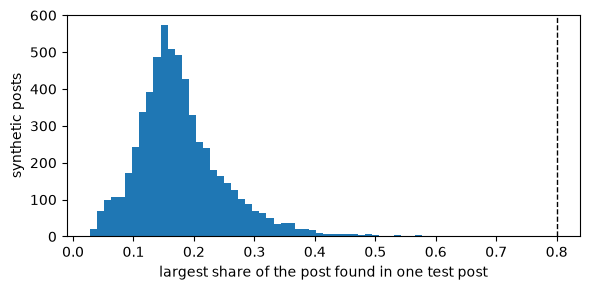

near-copies of a test post (80% or more): 0, 50% or more: 14


  half A: median 0.16, 50% or more: 6


  half B: median 0.14, 50% or more: 8


In [9]:
syn["copied_share"] = sd.max_copied_share(syn.text, test.text)
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(syn.copied_share, bins=50)
ax.axvline(0.8, color="k", ls="--", lw=1)
ax.set_xlabel("largest share of the post found in one test post")
ax.set_ylabel("synthetic posts")
plt.tight_layout()
plt.show()

print(f"near-copies of a test post (80% or more): {(syn.copied_share >= 0.8).sum()}, 50% or more: {(syn.copied_share >= 0.5).sum()}")
for h in "AB":
    share = sd.max_copied_share(syn.text, test.text[test.seed_half == h])
    print(f"  half {h}: median {np.median(share):.2f}, 50% or more: {(share >= 0.5).sum()}")

In [10]:
top_copy = syn.nlargest(3, "copied_share")
top_copy[["copied_share", "text"]].assign(text=lambda d: d.text.str.slice(0, 140).str.replace("\n", " "))

,copied_share,text
4423,0.611940,"Відновлюємо освітлення у Деснянському, Дарницькому та Дніпровському районах"
853,0.602410,Суд обрав запобіжний захист у вигляді тримання під вартою для підозрюваного у шахрайстві
3259,0.575342,Поліція відкрила кримінальне провадження через крадіжку в Деснянському районі


No post is a copy: the highest share is about 0.6, and those are posts that share stock phrases with a
test post ("у Дарницькому районі", "Повітряна тривога в Києві та області"), not text. The overlap with
half A, which the generator saw, is no higher than with half B, so the generator didn't copy its seeds.

Near-duplicates inside the synthetic set: for training we drop a post only when it shares half of its
pieces (Jaccard 0.5) with an earlier post, its near-twin. For a later grouped split we also keep the
looser repost groups of `tools.near_duplicate_groups`. Those chain through short posts, so one group
collects over a hundred different air-raid-alert posts, which is too much to throw away.

In [11]:
syn["repeats_earlier"] = sd.repeats_earlier(syn.text.tolist())
syn["duplicate_group"] = sd.near_duplicate_groups(syn.text.tolist())
group_size = syn.duplicate_group.map(syn.duplicate_group.value_counts())
print(f"posts with a near-twin earlier in the run: {syn.repeats_earlier.sum()}")
print(f"repost groups: {syn.duplicate_group.nunique()} for {len(syn)} posts, largest {group_size.max()}")
syn[syn.repeats_earlier].text.str.slice(0, 100).str.replace("\n", " ").head(5).to_frame()

posts with a near-twin earlier in the run: 196
repost groups: 5605 for 6079 posts, largest 113


,text
363,"💥 Вибухи у Дарницькому районі — ППО працює, залишайтеся в укриттях."
578,Київська міська рада ухвалила рішення збільшити фінансування шкільних їдалень на 15% у наступному бю
616,Київрада виділила 40 млн грн на ремонт доріг у Дарницькому районі
630,Міськрада ухвалила рішення збільшити фінансування шкільних їдалень на 12% з наступного бюджетного ро
667,Міська рада ухвалила рішення збільшити фінансування шкільних їдалень на 15% наступного року. Гроші п


## 6. Clean table for training

We drop, in this order: answers that are not a JSON list, rows with a string missing from the text,
near-copies of test posts (none this time), and posts with an earlier near-twin. What is left gets character
spans (`loc_markers`, the same format as the Kaggle files and `test_pseudo.parquet`), so the NER
training code can treat it like any other labeled data. We keep the group id so that a later split can
keep groups together.

In [12]:
syn["drop_reason"] = sd.drop_reason(syn, syn.copied_share.to_numpy())
summary = syn.drop_reason.replace("", "kept").value_counts()
summary["total"] = len(syn)
summary.to_frame("posts")

,posts
drop_reason,
kept,5839
near-duplicate of an earlier synthetic post,196
place not found in text,44
total,6079


In [13]:
clean = syn[syn.drop_reason == ""].copy()
clean["lang"] = sd.style(clean).lang
clean = clean[["syn_id", "text", "locations", "loc_markers", "lang", "duplicate_group", "copied_share"]].reset_index(drop=True)
clean.to_parquet(OUT / "full1_clean.parquet", index=False)

spans_ok = all(
    sorted({text[a:b] for a, b in m}) == sorted(set(locs))
    for text, locs, m in zip(clean.text, clean.locations, clean.loc_markers)
)
print(f"saved {len(clean)} posts to {(OUT / 'full1_clean.parquet').relative_to(ROOT.parent)}; "
      f"every span matches a label and every label has a span: {spans_ok}")
print(f"posts by language: {clean.lang.value_counts().to_dict()}, "
      f"mentions: {clean.loc_markers.str.len().sum()}, posts without places: {(clean.locations.str.len() == 0).mean():.0%}")

saved 5839 posts to synthetic/output/full1_clean.parquet; every span matches a label and every label has a span: True
posts by language: {'uk': 5316, 'ru': 523}, mentions: 8380, posts without places: 39%


## Summary

- The run gave 6,079 new posts. Format statistics (length, line breaks, emoji, language mix, places
  per post) are close to the test posts, thanks to the mutators.
- 44 rows had a label string with a different word ending than the text, and 196 were near-twins of
  another synthetic post. Both are dropped. No post copies a test post, and the generator stays as far
  from its seeds (half A) as from half B.
- The generator writes much more about Деснянський and Дарницький districts than the test posts do, and
  has a larger share of street names with a type word.
- These numbers only compare surface statistics. Whether XLM-R can still tell synthetic posts from test
  posts, and which synthetic posts look least like test, is the next notebook:
  `synthetic_adversarial.ipynb`.